# Chapter 1b: Class Imbalance

> **Data** clinic_escalations.csv · **Time** 45 min · **Needs first** C1, and train/test splitting

## What you will be able to do

1. Report the class balance of a dataset and say whether it is a problem
2. Explain why accuracy is the wrong metric for a rare positive class
3. Read a confusion matrix for an imbalanced problem
4. Apply RandomOverSampler, RandomUnderSampler and SMOTE, and state what each does to the training set
5. Use class_weight='balanced' and say how it differs from resampling
6. Choose between resampling, class weights and moving the threshold

## The one idea to hold on to

When the thing you care about is rare, accuracy measures how well you ignore it. Change the metric before you change the model.

This notebook covers techniques for handling imbalanced datasets, a common challenge in real-world machine learning problems.

**Prerequisites:**
- Completed C1_Data_Cleaning.ipynb
- Basic understanding of classification metrics

**Learning Objectives:**
- Understand what class imbalance is and why it matters
- Learn appropriate metrics for imbalanced data
- Apply resampling techniques (oversampling, undersampling, SMOTE)
- Use class weights in sklearn models

**Duration:** ~45 minutes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, 
    precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve
)

# For resampling
from sklearn.utils import resample

# Set random seed for reproducibility
np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. What is Class Imbalance?

Class imbalance occurs when one class significantly outnumbers the other(s) in a classification problem.

### Real-World Examples

| Domain | Minority Class | Typical Ratio |
|--------|---------------|---------------|
| Fraud Detection | Fraudulent transactions | 1:1000 |
| Medical Diagnosis | Rare disease cases | 1:100 to 1:10000 |
| Spam Detection | Spam emails | 1:10 |
| Churn Prediction | Customers who churn | 1:20 |
| Manufacturing | Defective products | 1:100 |

### Why It's a Problem

Standard classifiers optimize for **overall accuracy**, which can be misleading:
- A model predicting "Not Fraud" for everything achieves 99.9% accuracy but catches no fraud!
- The minority class (often the most important) gets ignored.

## 2. Load an Imbalanced Dataset

`clinic_escalations.csv` records 30,000 attendances at Northbridge Community Clinic.
300 of them escalated to emergency care: an escalation rate of 1.0%.

This file is generated by `data/generate_datasets.py`, which asserts on every build
that a plain logistic regression on it finds about 2% of the escalations while
scoring 98.98% accuracy, and that SMOTE and `class_weight` both recover most of the
recall. Those are the numbers this chapter is about, so they are tested rather than
hoped for.

Class Distribution:
  no escalation    29700 (99.00%)
  ESCALATED          300 (1.00%)


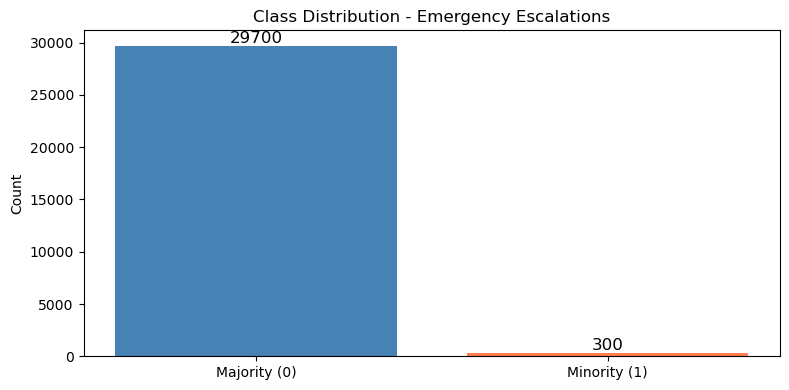

In [2]:
# Northbridge Community Clinic: 30,000 attendances, 300 of which escalated
# to emergency care. The escalation rate is 1.0%.
df = pd.read_csv('../../00-data/clinic_escalations.csv')

X = df.drop(columns=['visit_id', 'escalated'])
y = df['escalated'].values

# Check class distribution
unique, counts = np.unique(y, return_counts=True)
print("Class Distribution:")
for cls, cnt in zip(unique, counts):
    label = 'no escalation' if cls == 0 else 'ESCALATED'
    print(f"  {label:<15} {cnt:>6} ({cnt/len(y)*100:.2f}%)")

# Visualize
plt.figure(figsize=(8, 4))
plt.bar(['Majority (0)', 'Minority (1)'], counts, color=['steelblue', 'coral'])
plt.title('Class Distribution - Emergency Escalations')
plt.ylabel('Count')
for i, cnt in enumerate(counts):
    plt.text(i, cnt + 300, str(cnt), ha='center', fontsize=12)
plt.tight_layout()
plt.show()

In [3]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {len(X_train)} samples")
print(f"Test set: {len(X_test)} samples")
print(f"\nTraining class distribution: {np.bincount(y_train)}")

Training set: 24000 samples
Test set: 6000 samples

Training class distribution: [23760   240]


## 3. The Problem with Accuracy

Let's train a model and see why accuracy is misleading.

In [4]:
# Train a basic model
model_baseline = LogisticRegression(random_state=42, max_iter=1000)
model_baseline.fit(X_train, y_train)

# Predictions
y_pred = model_baseline.predict(X_test)

# Results
print("Baseline Model Results:")
print(f"Accuracy: {(y_pred == y_test).mean():.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Baseline Model Results:
Accuracy: 0.9898

Confusion Matrix:
[[5938    2]
 [  59    1]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      5940
           1       0.33      0.02      0.03        60

    accuracy                           0.99      6000
   macro avg       0.66      0.51      0.51      6000
weighted avg       0.98      0.99      0.99      6000



### Key Observation

Look at the **recall for class 1** (minority class). Even with high accuracy, the model may miss many positive cases!

In fraud detection, this means fraudulent transactions go undetected.

## 4. Better Metrics for Imbalanced Data

| Metric | Formula | Best For |
|--------|---------|----------|
| **Precision** | TP / (TP + FP) | When false positives are costly |
| **Recall** | TP / (TP + FN) | When false negatives are costly (fraud, disease) |
| **F1-Score** | 2 * (Precision * Recall) / (Precision + Recall) | Balance between precision and recall |
| **ROC-AUC** | Area under ROC curve | Overall model discrimination ability |
| **PR-AUC** | Area under Precision-Recall curve | Better for highly imbalanced data |

In [5]:
def evaluate_model(y_true, y_pred, y_prob=None, model_name="Model"):
    """Evaluate model with imbalanced-appropriate metrics."""
    print(f"\n{'='*50}")
    print(f"{model_name} Evaluation")
    print(f"{'='*50}")
    
    # Basic metrics
    print(f"Accuracy:  {(y_pred == y_true).mean():.4f}")
    print(f"Precision: {precision_score(y_true, y_pred):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
    print(f"F1-Score:  {f1_score(y_true, y_pred):.4f}")
    
    if y_prob is not None:
        print(f"ROC-AUC:   {roc_auc_score(y_true, y_prob):.4f}")
    
    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred)
    print(f"\nConfusion Matrix:")
    print(f"  TN={cm[0,0]}, FP={cm[0,1]}")
    print(f"  FN={cm[1,0]}, TP={cm[1,1]}")
    
    return {
        'accuracy': (y_pred == y_true).mean(),
        'precision': precision_score(y_true, y_pred),
        'recall': recall_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred)
    }

# Evaluate baseline
y_prob_baseline = model_baseline.predict_proba(X_test)[:, 1]
baseline_metrics = evaluate_model(y_test, y_pred, y_prob_baseline, "Baseline (No Handling)")


Baseline (No Handling) Evaluation
Accuracy:  0.9898
Precision: 0.3333
Recall:    0.0167
F1-Score:  0.0317
ROC-AUC:   0.8418

Confusion Matrix:
  TN=5938, FP=2
  FN=59, TP=1


## 5. Resampling Techniques

### 5.1 Random Oversampling

Duplicate samples from the minority class to balance the dataset.

In [6]:
# Separate majority and minority classes
X_majority = X_train[y_train == 0]
X_minority = X_train[y_train == 1]
y_majority = y_train[y_train == 0]
y_minority = y_train[y_train == 1]

print(f"Original - Majority: {len(X_majority)}, Minority: {len(X_minority)}")

# Oversample minority class
X_minority_upsampled, y_minority_upsampled = resample(
    X_minority, y_minority,
    replace=True,  # Sample with replacement
    n_samples=len(X_majority),  # Match majority class size
    random_state=42
)

# Combine
X_train_over = np.vstack([X_majority, X_minority_upsampled])
y_train_over = np.hstack([y_majority, y_minority_upsampled])

print(f"After Oversampling - Class 0: {sum(y_train_over==0)}, Class 1: {sum(y_train_over==1)}")

Original - Majority: 23760, Minority: 240
After Oversampling - Class 0: 23760, Class 1: 23760


In [7]:
# Train on oversampled data
model_over = LogisticRegression(random_state=42, max_iter=1000)
model_over.fit(X_train_over, y_train_over)

y_pred_over = model_over.predict(X_test)
y_prob_over = model_over.predict_proba(X_test)[:, 1]

over_metrics = evaluate_model(y_test, y_pred_over, y_prob_over, "Random Oversampling")


Random Oversampling Evaluation
Accuracy:  0.8505
Precision: 0.0599
Recall:    0.9500
F1-Score:  0.1128
ROC-AUC:   0.9263

Confusion Matrix:
  TN=5046, FP=894
  FN=3, TP=57


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


### 5.2 Random Undersampling

Remove samples from the majority class to balance the dataset.

In [8]:
# Undersample majority class
X_majority_downsampled, y_majority_downsampled = resample(
    X_majority, y_majority,
    replace=False,  # Sample without replacement
    n_samples=len(X_minority),  # Match minority class size
    random_state=42
)

# Combine
X_train_under = np.vstack([X_majority_downsampled, X_minority])
y_train_under = np.hstack([y_majority_downsampled, y_minority])

print(f"After Undersampling - Class 0: {sum(y_train_under==0)}, Class 1: {sum(y_train_under==1)}")

After Undersampling - Class 0: 240, Class 1: 240


In [9]:
# Train on undersampled data
model_under = LogisticRegression(random_state=42, max_iter=1000)
model_under.fit(X_train_under, y_train_under)

y_pred_under = model_under.predict(X_test)
y_prob_under = model_under.predict_proba(X_test)[:, 1]

under_metrics = evaluate_model(y_test, y_pred_under, y_prob_under, "Random Undersampling")


Random Undersampling Evaluation
Accuracy:  0.8480
Precision: 0.0572
Recall:    0.9167
F1-Score:  0.1076
ROC-AUC:   0.9230

Confusion Matrix:
  TN=5033, FP=907
  FN=5, TP=55


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


### 5.3 SMOTE (Synthetic Minority Over-sampling Technique)

SMOTE creates **synthetic** samples by interpolating between existing minority samples.

**How it works:**
1. For each minority sample, find its k nearest neighbors
2. Randomly select one neighbor
3. Create a new sample along the line between the original and neighbor

**Note:** Requires `imbalanced-learn` library: `pip install imbalanced-learn`

In [10]:
try:
    from imblearn.over_sampling import SMOTE
    
    # Apply SMOTE
    smote = SMOTE(random_state=42)
    X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
    
    print(f"After SMOTE - Class 0: {sum(y_train_smote==0)}, Class 1: {sum(y_train_smote==1)}")
    
    # Train on SMOTE data
    model_smote = LogisticRegression(random_state=42, max_iter=1000)
    model_smote.fit(X_train_smote, y_train_smote)
    
    y_pred_smote = model_smote.predict(X_test)
    y_prob_smote = model_smote.predict_proba(X_test)[:, 1]
    
    smote_metrics = evaluate_model(y_test, y_pred_smote, y_prob_smote, "SMOTE")
    
except ImportError:
    print("imbalanced-learn not installed. Install with: pip install imbalanced-learn")
    smote_metrics = None

After SMOTE - Class 0: 23760, Class 1: 23760



SMOTE Evaluation
Accuracy:  0.8683
Precision: 0.0634
Recall:    0.8833
F1-Score:  0.1183
ROC-AUC:   0.9237

Confusion Matrix:
  TN=5157, FP=783
  FN=7, TP=53


## 6. Class Weights

Many sklearn classifiers support `class_weight` parameter to penalize misclassifying minority class more heavily.

In [11]:
# Using class_weight='balanced'
model_weighted = LogisticRegression(
    random_state=42, 
    max_iter=1000,
    class_weight='balanced'  # Automatically adjusts weights inversely proportional to class frequencies
)
model_weighted.fit(X_train, y_train)

y_pred_weighted = model_weighted.predict(X_test)
y_prob_weighted = model_weighted.predict_proba(X_test)[:, 1]

weighted_metrics = evaluate_model(y_test, y_pred_weighted, y_prob_weighted, "Class Weights (balanced)")


Class Weights (balanced) Evaluation
Accuracy:  0.8500
Precision: 0.0597
Recall:    0.9500
F1-Score:  0.1124
ROC-AUC:   0.9260

Confusion Matrix:
  TN=5043, FP=897
  FN=3, TP=57


In [12]:
# Custom class weights
# Higher weight for minority class = more penalty for misclassifying it
model_custom = LogisticRegression(
    random_state=42, 
    max_iter=1000,
    class_weight={0: 1, 1: 10}  # Class 1 is 10x more important
)
model_custom.fit(X_train, y_train)

y_pred_custom = model_custom.predict(X_test)
y_prob_custom = model_custom.predict_proba(X_test)[:, 1]

custom_metrics = evaluate_model(y_test, y_pred_custom, y_prob_custom, "Custom Weights {0:1, 1:10}")


Custom Weights {0:1, 1:10} Evaluation
Accuracy:  0.9775
Precision: 0.1560
Recall:    0.2833
F1-Score:  0.2012
ROC-AUC:   0.8951

Confusion Matrix:
  TN=5848, FP=92
  FN=43, TP=17


## 7. Comparison Summary

In [13]:
# Compile results
results = pd.DataFrame({
    'Method': ['Baseline', 'Oversampling', 'Undersampling', 'Class Weights'],
    'Accuracy': [baseline_metrics['accuracy'], over_metrics['accuracy'], 
                 under_metrics['accuracy'], weighted_metrics['accuracy']],
    'Precision': [baseline_metrics['precision'], over_metrics['precision'],
                  under_metrics['precision'], weighted_metrics['precision']],
    'Recall': [baseline_metrics['recall'], over_metrics['recall'],
               under_metrics['recall'], weighted_metrics['recall']],
    'F1-Score': [baseline_metrics['f1'], over_metrics['f1'],
                 under_metrics['f1'], weighted_metrics['f1']]
})

# Add SMOTE if available
if smote_metrics:
    smote_row = pd.DataFrame({
        'Method': ['SMOTE'],
        'Accuracy': [smote_metrics['accuracy']],
        'Precision': [smote_metrics['precision']],
        'Recall': [smote_metrics['recall']],
        'F1-Score': [smote_metrics['f1']]
    })
    results = pd.concat([results, smote_row], ignore_index=True)

print("\n" + "="*70)
print("COMPARISON SUMMARY")
print("="*70)
print(results.round(4).to_string(index=False))


COMPARISON SUMMARY
       Method  Accuracy  Precision  Recall  F1-Score
     Baseline    0.9898     0.3333  0.0167    0.0317
 Oversampling    0.8505     0.0599  0.9500    0.1128
Undersampling    0.8480     0.0572  0.9167    0.1076
Class Weights    0.8500     0.0597  0.9500    0.1124
        SMOTE    0.8683     0.0634  0.8833    0.1183


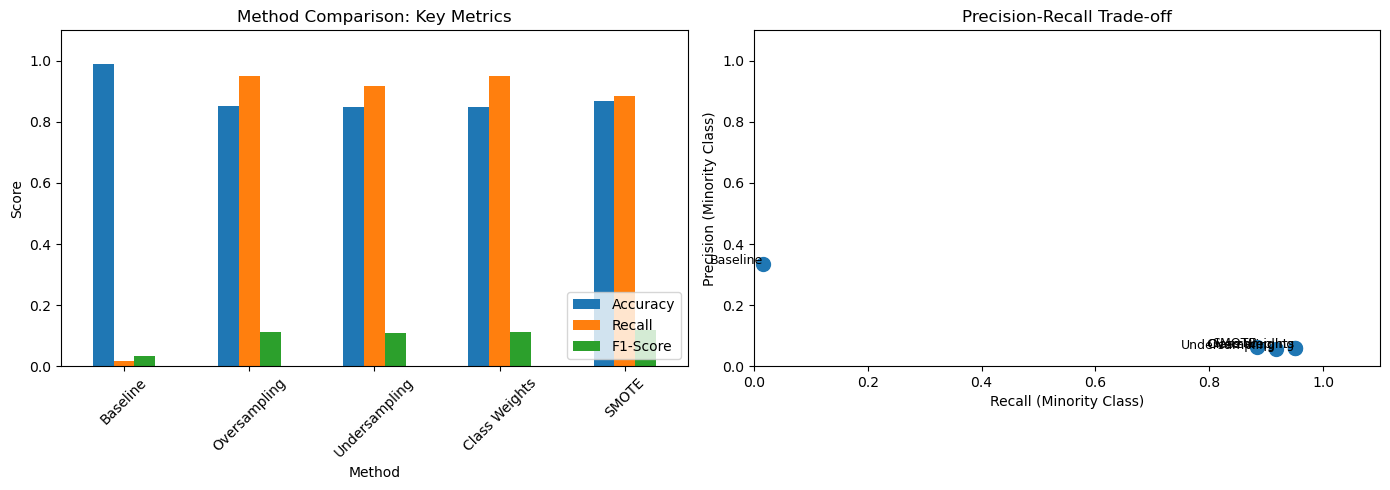

In [14]:
# Visualize comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Metrics comparison
metrics_to_plot = results.set_index('Method')[['Accuracy', 'Recall', 'F1-Score']]
metrics_to_plot.plot(kind='bar', ax=axes[0], rot=45)
axes[0].set_title('Method Comparison: Key Metrics')
axes[0].set_ylabel('Score')
axes[0].legend(loc='lower right')
axes[0].set_ylim(0, 1.1)

# Precision-Recall trade-off
axes[1].scatter(results['Recall'], results['Precision'], s=100)
for i, method in enumerate(results['Method']):
    axes[1].annotate(method, (results['Recall'][i], results['Precision'][i]), 
                    fontsize=9, ha='right')
axes[1].set_xlabel('Recall (Minority Class)')
axes[1].set_ylabel('Precision (Minority Class)')
axes[1].set_title('Precision-Recall Trade-off')
axes[1].set_xlim(0, 1.1)
axes[1].set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

## 8. When to Use Each Technique

| Technique | Best For | Pros | Cons |
|-----------|----------|------|------|
| **Random Oversampling** | Small datasets | Simple, no info loss | Overfitting risk |
| **Random Undersampling** | Large datasets | Faster training | Loses information |
| **SMOTE** | Medium imbalance | Creates realistic samples | Can create noisy samples |
| **Class Weights** | Any size | No data modification | May not be enough for extreme imbalance |

### Guidelines

1. **Start with class weights** - simplest approach, no data modification
2. **Try SMOTE** for moderate imbalance (1:10 to 1:100)
3. **Use undersampling** when you have abundant data
4. **Combine techniques** for extreme cases (e.g., SMOTE + undersampling)
5. **Always evaluate on the original test set** - never resample test data!

---

## Exercise

Using the wine dataset with engineered imbalance:

1. Load wine data and create imbalanced version (keep only 10% of class 1)
2. Train a Random Forest classifier without any handling
3. Apply SMOTE and retrain
4. Use class_weight='balanced' and retrain
5. Compare recall scores for the minority class

In [15]:
# Exercise: Your code here
from sklearn.datasets import load_wine

# Load wine dataset
wine = load_wine()
X_wine = wine.data
y_wine = (wine.target == 2).astype(int)  # Binary: class 2 vs rest

# TODO: Create imbalanced version by removing 90% of class 1 samples

# TODO: Split data

# TODO: Train baseline model

# TODO: Apply SMOTE and train

# TODO: Train with class_weight='balanced'

# TODO: Compare results

---

## Summary

**Key Takeaways:**

1. **Accuracy is misleading** for imbalanced data - use Precision, Recall, F1, ROC-AUC
2. **Resampling** can balance the training data:
   - Oversampling duplicates minority samples
   - Undersampling removes majority samples
   - SMOTE creates synthetic minority samples
3. **Class weights** penalize misclassifying minority class more heavily
4. **Never resample test data** - evaluate on original distribution
5. **Choose based on context** - what's worse: missing fraud or flagging legitimate transactions?

**Next:** Continue to C2_Feature_Scaling.ipynb

---

## How this is used in real work

Fraud, fault prediction, churn, disease screening and every alerting system you will ever build are this problem. `class_weight='balanced'` is one keyword argument and usually the first thing to try; SMOTE is `imblearn`'s most-used class. Resample the TRAINING fold only, never the test set, or you are scoring the model on data it invented.

## Where this goes next

**C2** scaling. Note that SMOTE interpolates between neighbours, so it needs scaled features to behave sensibly.